# Part 6: Regression Topics {-}

In [1]:
import warnings
warnings.filterwarnings(action='ignore')

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

## Categorical Predictors {-}

One often encounters variables which are discrete quantities, but still
are on the **ratio scale**, meaning that for that variable it makes
sense to say things such as "Indvidual A has value for this variable
which is twice as large as the value for Individual B."

A primary example is that of a **count variable**, i.e., a variable that
measures the number of times something happens, or the number of items of
a certain type.

For example, it is standard for credit-granting entities to build models 
where the response variable is the likelihood someone will pay off a loan
and the predictors utilized include counts such as

1. the number of major derogatory reports on credit record
2. the number of dependents
3. the number of major credit cards held
4. the number of active credit accounts

Such variables **can** be included as predictors in a linear model just as continuous quantites are; the interpretation remains that same: The mean model increases as a linear function of the variable.

\newpage

There are some discrete variables for which it is clearly not a good
idea to include them in the manner described above, however.
These include cases of **categorical variables** where the values are not on the ratio scale.

**Exercise:** Consider a variable which indicates highest degree obtained:

* 0 = Did not finish high school
* 1 = Finished some high school
* 2 = Some college
* 3 = Graduated from college

This variable is on the **ordinal scale**, meaning that there is a natural
ordering to the levels, but ratios of values do not have meaning. 
What would happen if we mistakenly treated this as
a variable on the ratio scale when including it in the regression model?

\answerlines{8}

\newpage

**Important to note:** A categorical variable with $k$ levels adds $k-1$ parameters into the regression model.

To see why this is the case, imagine that the model under
consideration includes a predictor giving the number of credit cards,
along with this education level predictor.
The $k-1$ new terms correspond to
"shifts" in the mean model relative to the "baseline"
category. In particular, let $X$ equal the number of credit cards. Then,

* when the education level is 0, then the mean model is $\beta_0 + \beta_4 X$
* when the education level is 1, then the mean model is $\beta_0 + \beta_4 X + \beta_1$
* when the education level is 2, then the mean model is $\beta_0 + \beta_4 X + \beta_2$
* when the education level is 3, then the mean model is $\beta_0 + \beta_4 X + \beta_3$

We can write this mean model more compactly as
\begin{equation*}
   \beta_0 +  
   \beta_1 {\bf 1}_{\{\mbox{\small edu $= 1$\}}} +
   \beta_2 {\bf 1}_{\{\mbox{\small edu $= 2$\}}} +
   \beta_3 {\bf 1}_{\{\mbox{\small edu $= 3$\}}} +
   \beta_4 X
\end{equation*}
where ${\bf 1}_A$ is the **indicator variable** for the event $A$.

**Exercise:** Why not include **every** discrete predictor as being categorical?

\answerlines{5}

In [2]:
np.random.seed(2)

NumCards_init = np.array([4, 2, 1, 5, 4, 2])
Education_init = np.array([2, 3, 2, 0, 1, 0])

NumCards_rand = np.random.poisson(lam=2.5, size=94)
Education_rand = np.random.choice([0, 1, 2, 3], size=94, replace=True)

NumCards = np.concatenate([NumCards_init, NumCards_rand])
Education = np.concatenate([Education_init, Education_rand])

noise = np.random.normal(loc=0, scale=3, size=100)
y = np.round(35 + NumCards*(-2) + 5*(Education==1) + 7*(Education==2) + 10*(Education==3) + noise)

df = pd.DataFrame({'PS': y, 'Education': Education, 'NumCards': NumCards})

\newpage

An appropriately-defined categorical variable will be handled correctly by software. In Pandas, a column of a data frame is specified as being categorical by using the `.astype('category')` syntax:

In [3]:
df['Education'] = df['Education'].astype('category')

Now consider the output from the regression fit:

In [4]:
holdlm = sm.OLS.from_formula('PS ~ NumCards + Education', data=df).fit()
holdlm.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,35.2816,0.943,37.419,0.000,33.410,37.154
Education[T.1],4.7608,0.964,4.938,0.000,2.847,6.675
Education[T.2],6.4110,0.929,6.900,0.000,4.566,8.256
Education[T.3],11.2058,1.065,10.520,0.000,9.091,13.321
NumCards,-1.9260,0.202,-9.518,0.000,-2.328,-1.524


**Exercise:** Consider the sample output above. What is the expected response for a case when education level is "Did not finish high school?" What about when education level is "Some college?"

\answerlines{7}

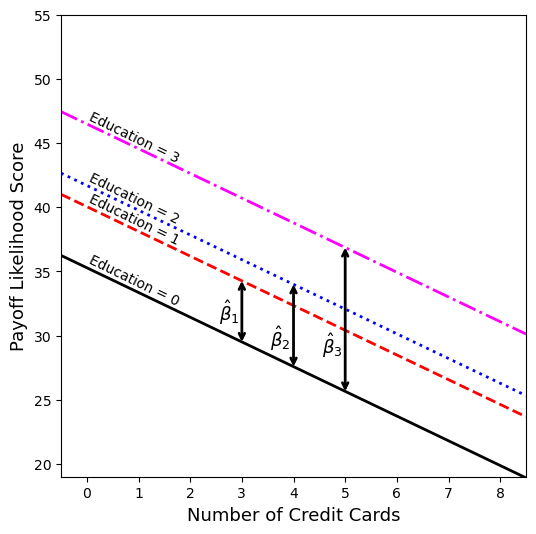

In [5]:
b0,b1,b2,b3,b4 = holdlm.params

plt.figure(figsize=(6, 6))

plt.xlim(NumCards.min() - 0.5, NumCards.max() + 0.5)
plt.ylim(y.min() - 2, y.max() + 5)
plt.xlabel("Number of Credit Cards", fontsize=13)
plt.ylabel("Payoff Likelihood Score", fontsize=13)

# X values to draw the lines across the plot
x_vals = np.array(plt.xlim())

# Draw the 4 parallel regression lines
plt.plot(x_vals, b0 + b4 * x_vals, color='black', linewidth=2, linestyle='-')
plt.plot(x_vals, b0 + b1 + b4 * x_vals, color='red', linewidth=2, linestyle='--')
plt.plot(x_vals, b0 + b2 + b4 * x_vals, color='blue', linewidth=2, linestyle=':')
plt.plot(x_vals, b0 + b3 + b4 * x_vals, color='magenta', linewidth=2, linestyle='-.')

# Add rotated text labels
textang = -26
offs = 1
plt.text(0, b0 - offs, "Education = 0", rotation=textang, ha='left', va='center')
plt.text(0, b0 + b1 - offs, "Education = 1", rotation=textang, ha='left', va='center')
plt.text(0, b0 + b2 - offs, "Education = 2", rotation=textang, ha='left', va='center')
plt.text(0, b0 + b3 - offs, "Education = 3", rotation=textang, ha='left', va='center')

arrow_kwargs = dict(arrowstyle='<->', lw=2, color='black', shrinkA=0, shrinkB=0)

# Arrow 1 for Beta 2
y1_arr1 = b0 + 3 * b4
y2_arr1 = b0 + 3 * b4 + b1
plt.annotate('', xy=(3, y2_arr1), xytext=(3, y1_arr1), arrowprops=arrow_kwargs)
plt.text(2.95, (y1_arr1 + y2_arr1) / 2, r"$\hat{\beta}_1$", fontsize=13, ha='right', va='center')

# Arrow 2 for Beta 3
y1_arr2 = b0 + 4 * b4
y2_arr2 = b0 + 4 * b4 + b2
plt.annotate('', xy=(4, y2_arr2), xytext=(4, y1_arr2), arrowprops=arrow_kwargs)
plt.text(3.95, ((y1_arr2 + y2_arr2) / 2) - 1, r"$\hat{\beta}_2$", fontsize=13, ha='right', va='center')

# Arrow 3 for Beta 4
y1_arr3 = b0 + 5 * b4
y2_arr3 = b0 + 5 * b4 + b3
plt.annotate('', xy=(5, y2_arr3), xytext=(5, y1_arr3), arrowprops=arrow_kwargs)
plt.text(4.95, ((y1_arr3 + y2_arr3) / 2) - 2, r"$\hat{\beta}_3$", fontsize=13, ha='right', va='center')

plt.show()

Note how, in the figure above, the slope of the relationship between the number of credit cards and the expected response is the same for each education level. The different education levels induce a shift in the line, but not its slope.

\newpage

**Categorical Variables in the Design Matrix**

Recall that a categorical variable with $k$ levels adds $k-1$ $\beta$ parameters
to the model. Hence, it adds $k-1$ **columns** to the design matrix ${\bf X}$.
In order to create the "shifting" effect,
these columns will be filled with zeros and ones.

Consider the synthetic data set constructed above.

In [6]:
df.head()

,PS,Education,NumCards
0,33.0,2,4
1,45.0,3,2
2,44.0,2,1
3,28.0,0,5
4,31.0,1,4


The first five rows of the design matrix would be
\begin{equation*}
   {\bf X} = \left[
   \begin{array}{cccccc}
   \: 1 \:  & \: 0 \: & \: 1 \: & \: 0 \: & \: 4 \:\\
   1  & 0 & 0 & 1 & 2\\
   1  & 0 & 1 & 0 & 1\\
   1  & 0 & 0 & 0 & 5\\
   1  & 1 & 0 & 0 & 4\\
   \vdots & \vdots & \vdots & \vdots & \vdots \\
   \end{array}
   \right]
\end{equation*}

\newpage

The operation of converting a categorical variable into 
columns of indicator
functions for each level is referred to as **one-hot encoding** of the variable.

The function `get_dummies` in Pandas will convert any variable
labelled as categorical in a data frame into appropriate columns of indicator variables. The first
level will be used as the reference category provided that `drop_first` is
set to `True`. Note that the default value for `drop_first` is `False`, and the
result will be an extra, unwanted column for each categorical variable. Set `dtype=float` in order to obtain 0/1 entries.

In [7]:
pd.get_dummies(df, drop_first=True, dtype=float)

,PS,NumCards,Education_1,Education_2,Education_3
0,33.0,4,0.0,1.0,0.0
1,45.0,2,0.0,0.0,1.0
2,44.0,1,0.0,1.0,0.0
3,28.0,5,0.0,0.0,0.0
4,31.0,4,1.0,0.0,0.0
...,...,...,...,...,...
95,43.0,1,0.0,1.0,0.0
96,41.0,2,0.0,1.0,0.0
97,43.0,2,0.0,0.0,1.0
98,38.0,5,0.0,1.0,0.0


\newpage

**Exercise:** Suppose that a model contains only two predictors, and they
are both categorical variables. The first $(X_1)$ has three levels, and the second $(X_2)$ has four
levels. How many total $\beta$ parameters are in the model, and how is each interpreted?

\answerlines{20}

\newpage

## Interactions {-}

**Interaction** terms are added to the model by taking the product
of other predictors.

In the absence of any interactions, we say that the model is 
**additive** in the predictors.

**Exercise:** Think carefully about what is
being assumed when an additive model is used. In particular, what
is the effect on the mean model if a covariate is varied?

\answerlines{7}

\newpage

Consider a model with two predictor variables $X_1$ and $X_2$, but with the interaction term $X_1 X_2$ included. So, the mean model is
\begin{equation*}
   \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \beta_3 X_1 X_2
\end{equation*}

Then, if $X_1$ is held fixed, the effect of varying $X_2$ is
characterized by the slope of $\beta_2 + \beta_3 X_1$.
In other words, if $X_2$ is increased by $c$, then the expected
response increases by $(\beta_2 + \beta_3 X_1)c$.
The key enhancement is that this slope now depends on $X_1$.

Of course, one may wonder: Why does it make sense to
let the slope depend on $X_1$ **in this particular manner**?

The best way to answer this is to consider the interaction
$X_1 X_2$ to be a **first order approximation** to this
dependence.

It is much like how we often use straight lines to approximate
relationships which are not truly straight: These are useful
approximations in the right circumstances.

\newpage

**Exercise:** What will happen if you include in the model
an interaction between a predictor on the ratio scale variable and a categorical variable?

\answerlines{18}

\newpage

## Making Predictions {-}

One of the fundamental motivations for using regression models is to make predictions
for **future** observations of the response. In other words, consider a situation
where you know the value of the predictor variable $x$, and seek to predict the response.

In the context of our simple linear regression model, if our value for the predictor
is $x^*$, then we would start by finding
\begin{equation*}
   \widehat y^* = \widehat \beta_0 + \widehat \beta_1 x^*
\end{equation*}
We have plugged in this new value for $x$ into the line that has been fit.
This is our best estimator for $y^*$, the true response for this object.

One should not be satisfied with only this, however: We should quantify the amount of
error in this prediction.

\newpage

In the case of simple linear regression,
the **variance in the error in the prediction** is
\begin{equation*}
  V\!\left(\widehat y^* - y^*\right)
   = \sigma^2 + \sigma^2\!\left[\frac{1}{n} + \frac{\left(x^* - \overline{x}\right)^2}{(n-1)s_x^2}\right]
\end{equation*}

**Exercise:** Explain how the above decomposes the error in
the prediction into two key sources.

\answerlines{7}

Hence the **standard error in the prediction** is
\begin{equation*}
  \mbox{SE}(\widehat y^*)
   = \sqrt{\sigma^2 + \sigma^2\!\left[\frac{1}{n} + \frac{\left(x^* - \overline{x}\right)^2}{(n-1)s_x^2}\right]}
\end{equation*}

In practice $\sigma^2$ will be replaced with $\widehat \sigma^2$.

\newpage

If the errors are assumed to be normally distributed, then
a **$100(1-\alpha)\%$** prediction interval for the future response} can be written as
\begin{equation*}
   \widehat y^* \pm t_{\alpha/2, n-2} \:\mbox{SE}(\widehat y^*)
\end{equation*}
or, when the sample size is not small,
\begin{equation*}
   \widehat y^* \pm z_{\alpha/2} \:\mbox{SE}(\widehat y^*).
\end{equation*}

The figure below shows a simple example of how the prediction interval
will appear, as $x^*$ ranges over the extent of the predictor space.

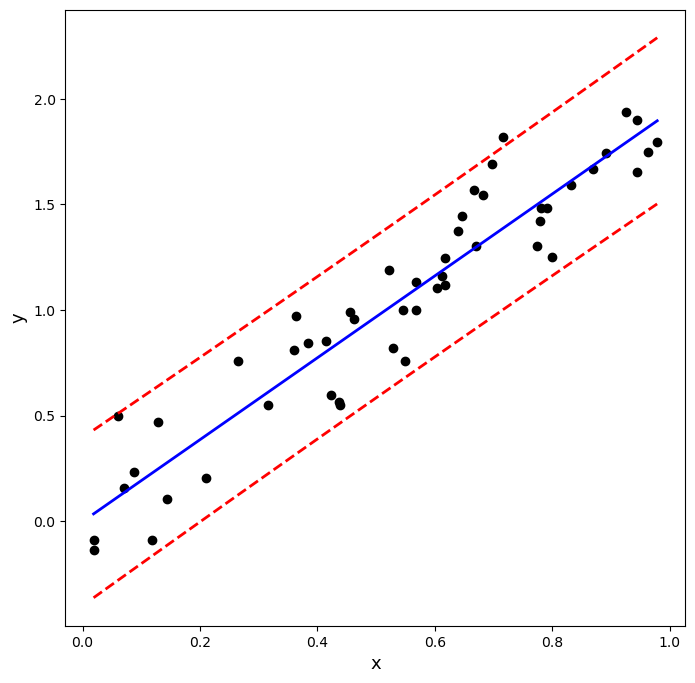

In [8]:
n = 50

# Set seed for reproducibility
np.random.seed(0)

# Generate data
x = np.random.uniform(0, 1, n)
y = 2 * x + np.random.normal(loc=0, scale=0.2, size=n)

# Create a DataFrame to fit the model
df = pd.DataFrame({'x': x, 'y': y})

# Fit the linear model
holdlm2 = sm.OLS.from_formula('y ~ x', data=df).fit()

# Create a sequence of 100 evenly spaced x values from min(x) to max(x)
xseq = np.linspace(x.min(), x.max(), 100)
df_pred = pd.DataFrame({'x': xseq})

# Get predictions and prediction intervals
# get_prediction() calculates the standard errors and intervals
predictions = holdlm2.get_prediction(df_pred)
pred_summary = predictions.summary_frame(alpha=0.05) # alpha=0.05 gives the default 95% interval

# Set up the plot
plt.figure(figsize=(8, 8))

# Scatter plot of the actual data (pch=16 is a solid circle)
plt.scatter(x, y, color='black', marker='o')

# Plot the main regression line (col=4 in R is blue)
plt.plot(xseq, pred_summary['mean'], color='blue', linewidth=2)

# Plot the lower and upper prediction intervals (col=2 in R is red, lty=2 is dashed)
plt.plot(xseq, pred_summary['obs_ci_lower'], color='red', linewidth=2, linestyle='--')
plt.plot(xseq, pred_summary['obs_ci_upper'], color='red', linewidth=2, linestyle='--')

# Set labels and axis font sizes
plt.xlabel("x", fontsize=13)
plt.ylabel("y", fontsize=13)

plt.show()

\newpage

**Exercise:** Discuss the role of the normality assumption in the validity of this interval. If the sample size is large, do you believe that the normality assumption can be relaxed?

\answerlines{10}

\newpage

In Python, the function `get_prediction` will construct prediction intervals. Note that the predictor values must be passed in as a data frame with the same variable names as the original fit.

Also, be careful with the output. The `obs_ci_lower` and `obs_ci_upper` are a 95% prediction interval for the response value. The `mean_ci_lower` and `mean_ci_upper` are a 95% confidence interval for the mean model at these predictor values.

In [9]:
dfp = pd.DataFrame({'Education':[0,3,2],'NumCards':[2,3,2]})

preds = holdlm.get_prediction(dfp)
preds.summary_frame(alpha=0.05)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,31.429681,0.754785,29.931244,32.928117,24.778439,38.080922
1,40.709495,0.778559,39.163860,42.255130,34.047462,47.371528
2,37.840656,0.577706,36.693765,38.987547,31.259694,44.421618


**Exercise:** Why are the reported confidence intervals smaller than the reported prediction intervals?
    
\answerlines{5}